In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.metrics import root_mean_squared_error, mean_absolute_error , r2_score
from sklearn.base import clone

In [4]:
df = pd.read_csv("./housing.csv").dropna()
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_household"] = df["total_bedrooms"] / df["households"]
df["population_per_household"] = df["population"] / df["households"]

In [5]:
X = df.drop(columns=["median_house_value", "total_rooms", "total_bedrooms", "population"])
y = df["median_house_value"]

In [6]:
x_train_val, x_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
x_train, x_val, y_train, y_val = train_test_split(
    x_train_val, y_train_val, test_size=0.25, random_state=42 # 0.25 * 0.8 = 0.2
)

In [7]:
skewed_cols = ["households", "rooms_per_household", "bedrooms_per_household", "population_per_household"]
for split in (x_train, x_val, x_test):
    for col in skewed_cols:
        split[col] = np.log1p(split[col])

In [8]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoder.set_output(transform="pandas")

train_cat = encoder.fit_transform(x_train[["ocean_proximity"]])
val_cat = encoder.transform(x_val[["ocean_proximity"]])
test_cat = encoder.transform(x_test[["ocean_proximity"]])

In [9]:
x_train_prep = pd.concat([x_train.drop(columns=["ocean_proximity"]), train_cat], axis=1)
x_val_prep = pd.concat([x_val.drop(columns=["ocean_proximity"]), val_cat], axis=1)
x_test_prep = pd.concat([x_test.drop(columns=["ocean_proximity"]), test_cat], axis=1)

In [10]:
# scale 
num_cols = [c for c in x_train_prep.columns if not c.startswith("ocean_proximity_")]
scaler = StandardScaler()
x_train_prep[num_cols] = scaler.fit_transform(x_train_prep[num_cols])
x_val_prep[num_cols] = scaler.transform(x_val_prep[num_cols])
x_test_prep[num_cols] = scaler.transform(x_test_prep[num_cols])

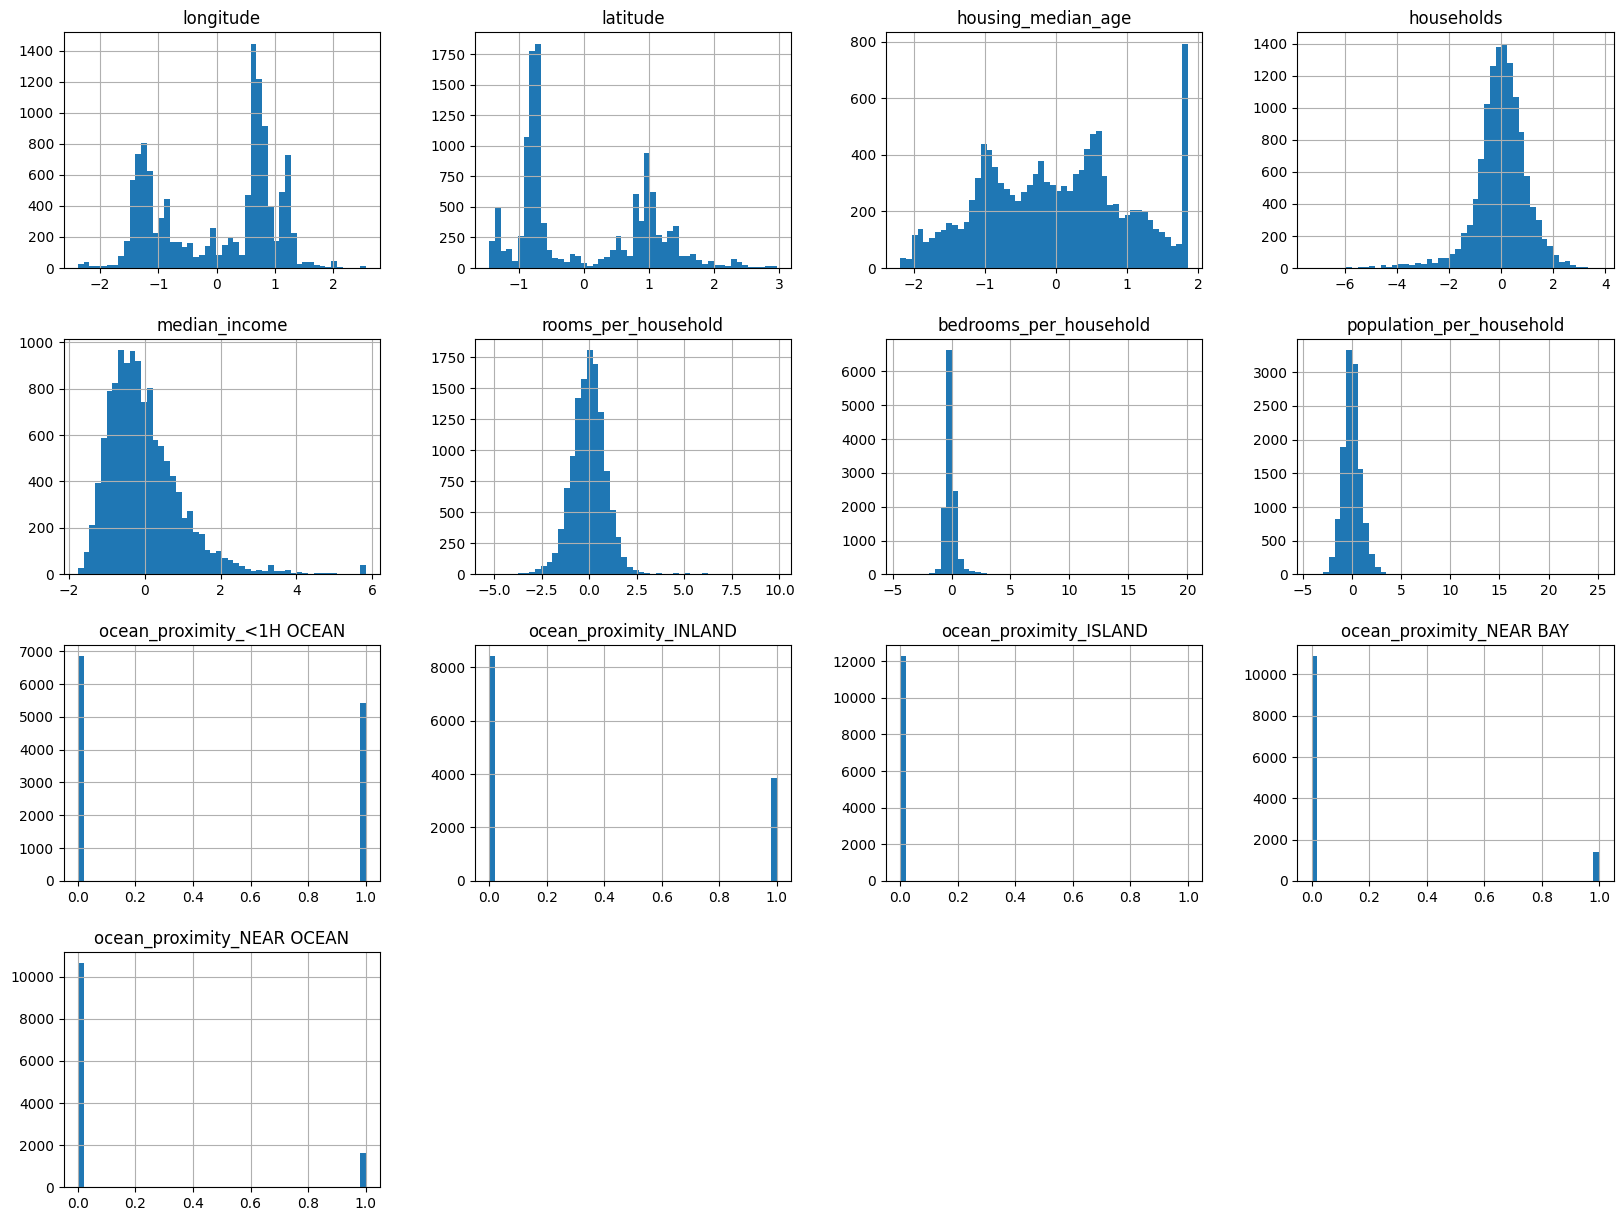

In [11]:
x_train_prep.hist(bins=50,figsize=(20,15))
plt.show()

In [12]:
def eval_model(model,x_tr,y_tr,x_ev,y_ev):
    model.fit(x_tr,y_tr)
    preds = model.predict(x_ev)
    rmse = root_mean_squared_error(y_ev,preds)
    mae = mean_absolute_error(y_ev,preds)
    return rmse, mae, preds

In [ ]:
best_ridge = {"rmse": float("inf")}
for alpha in [0.01, 0.1, 1.0, 10.0, 100.0]:
    model = Ridge(alpha=alpha)
    rmse, mae, _ = eval_model(model, x_train_prep, y_train, x_val_prep, y_val)
    if rmse < best_ridge["rmse"]:
        best_ridge = {"rmse": rmse, "alpha": alpha, "model": model}

In [40]:
best_ridge

{'rmse': 66433.08952429987, 'alpha': 0.01, 'model': Ridge(alpha=0.01)}

In [15]:
best_lin_svr = {"rmse": float("inf")}
for C in [0.1, 1.0, 10.0]:
    for eps in [0.01, 0.1, 0.2]:
        model = TransformedTargetRegressor(
            regressor=SVR(kernel="linear", C=C, epsilon=eps),
            transformer=StandardScaler()
        )
        rmse, mae, _ = eval_model(model, x_train_prep, y_train, x_val_prep, y_val)
        if rmse < best_lin_svr["rmse"]:
            best_lin_svr = {"rmse": rmse, "C": C, "eps": eps, "model": model}

In [16]:
best_lin_svr

{'rmse': 66845.56963954515,
 'C': 10.0,
 'eps': 0.2,
 'model': TransformedTargetRegressor(regressor=SVR(C=10.0, epsilon=0.2, kernel='linear'),
                            transformer=StandardScaler())}

In [ ]:
best_rbf_svr = {"rmse": float("inf")}
for C in [1.0, 10.0, 50.0]:
    for eps in [0.05, 0.1, 0.2]:
        for gamma in ["scale", 0.05, 0.1, 0.5]:
            model = TransformedTargetRegressor(
                regressor=SVR(kernel="rbf", C=C, epsilon=eps, gamma=gamma),
                transformer=StandardScaler()
            )
            rmse, mae, _ = eval_model(model, x_train_prep, y_train, x_val_prep, y_val)
            if rmse < best_rbf_svr["rmse"]:
                best_rbf_svr = {"rmse": rmse, "C": C, "eps": eps, "gamma": gamma, "model": model}

In [41]:
best_rbf_svr

{'rmse': 51637.58840568211,
 'C': 10.0,
 'eps': 0.1,
 'gamma': 'scale',
 'model': TransformedTargetRegressor(regressor=SVR(C=10.0), transformer=StandardScaler())}

In [42]:
models = {
    "Ridge": best_ridge["model"],
    "Linear SVR": best_lin_svr["model"],
    "RBF SVR": best_rbf_svr["model"],
}

results = []
test_preds = {}

for name, model in models.items():
    preds = model.predict(x_test_prep)
    test_preds[name] = preds
    results.append({
        "Model": name,
        "Test RMSE": root_mean_squared_error(y_test, preds),
        "Test MAE": mean_absolute_error(y_test, preds),
        "R2" : r2_score(y_test,preds)
    })

In [43]:
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

     Model    Test RMSE     Test MAE       R2
     Ridge 67888.702847 49030.537819 0.662975
Linear SVR 68831.109122 48079.848371 0.653553
   RBF SVR 53358.920907 35089.388217 0.791800


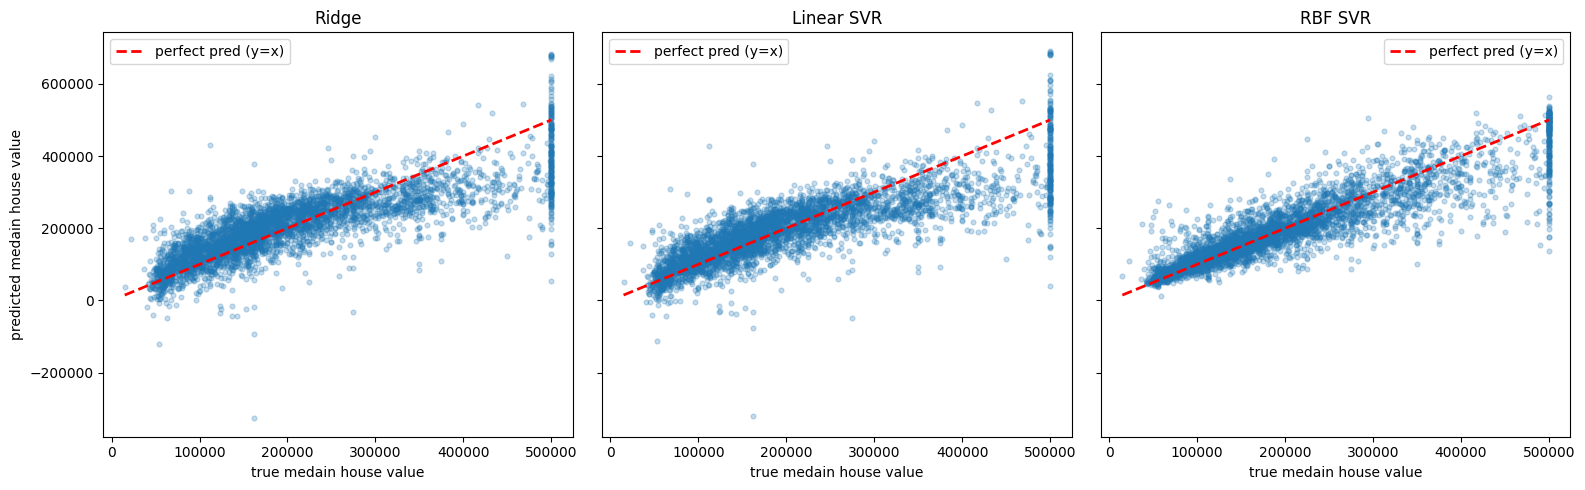

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
min_val, max_val = y_test.min(), y_test.max()

for ax, (name, preds) in zip(axes, test_preds.items()):
    ax.scatter(y_test, preds, alpha=0.25, s=12)
    ax.plot([min_val, max_val], [min_val, max_val], "r--", lw=2, label="perfect pred (y=x)")
    ax.set_title(name)
    ax.set_xlabel("true medain house value")
    ax.legend()

axes[0].set_ylabel("predicted medain house value")
plt.tight_layout()
plt.show()

In [55]:
best_C = best_rbf_svr["C"]
best_gamma = best_rbf_svr["gamma"]
best_eps = best_rbf_svr["eps"]

# since y is already scaled so epsilon on dollar scale is of no sense
epsilons = [0.0, 0.01, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0, 1.5]

In [57]:
sv_fractions = []
test_rmses = []

n_train = x_train_prep.shape[0]
for eps in epsilons:
    model = clone(best_rbf_svr["model"])
    model.set_params(regressor__epsilon=eps)
    model.fit(x_train_prep, y_train)
    
    sv_fractions.append(len(model.regressor_.support_) / n_train)
    test_rmses.append(root_mean_squared_error(y_test, model.predict(x_test_prep)))

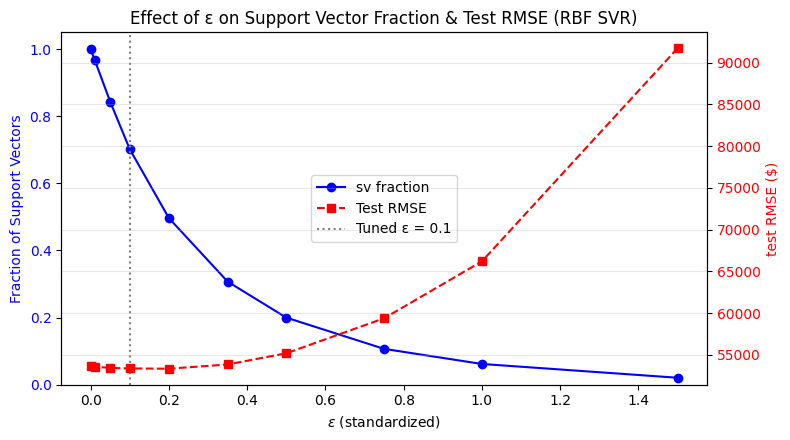

In [70]:
fig, ax1 = plt.subplots(figsize=(8, 4.5))

ax1.set_xlabel(r"$\varepsilon$ (standardized)")
ax1.set_ylabel("Fraction of Support Vectors", color="blue")
l1 = ax1.plot(epsilons, sv_fractions, marker="o", color="blue", label="sv fraction")
ax1.tick_params(axis="y", labelcolor="blue")
ax1.set_ylim(0, 1.05)

ax2 = ax1.twinx()
ax2.set_ylabel("test RMSE ($)", color="red")
l2 = ax2.plot(epsilons, test_rmses, marker="s", linestyle="--", color="red", label="Test RMSE")
ax2.tick_params(axis="y", labelcolor="red")

l3 = ax1.axvline(best_eps, color="gray", linestyle=":", label=f"Tuned ε = {best_eps}")

lines = l1 + l2 + [l3]
ax1.legend(lines, [l.get_label() for l in lines], loc="center")
plt.title("Effect of ε on Support Vector Fraction & Test RMSE (RBF SVR)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()